### iShares iBoxx $ High Yield Corporate Bond ETF

In [1]:
import os
import sys
import requests
import datetime as dt
import numpy as np
from dotenv import load_dotenv
from pathlib import Path
import requests
import pandas as pd
import talib as ta
import plotly.graph_objs as go

import ipywidgets as widgets
from ipywidgets import Dropdown, Text, Button, Output
from IPython.display import display

from Modules.utility import Utility
from Modules.show_plot import ShowPlot
from Modules.reques_api import RequestApi
from Modules.get_market_data import GetMarketData
from Modules.stock_prices_and_market_data import ClassStockPricesMarketData
from Modules.financial import Financial
from Modules.pdf_url_to_markdown import PDFUrlToMarkdown
from Modules.webpage_to_markdown import WebpageToMarkdown
from Modules.compute_fibonacci_extension import ComputeFibonacciExtension

In [2]:
API_BASE_URL = os.getenv("API_BASE_URL", "http://localhost:8000")
request_api = RequestApi(API_BASE_URL)
get_market_data = GetMarketData(Path('/workspace/data'))
utility = Utility()
stock_prices_market_data = ClassStockPricesMarketData()
financial = Financial()
# URLからPDFをダウンロードしてMarkdownに変換するクラスのインスタンスを作成
pdf_to_md = PDFUrlToMarkdown()
# WEBページをMarkdownに変換する関数
webpage_to_markdown = WebpageToMarkdown()
# Fibonacciエクステンションを計算するクラスのインスタンスを作成
fibonacci_extension = ComputeFibonacciExtension()

In [3]:
start = '1999-01-01'
end = dt.datetime.now().strftime('%Y-%m-%d')

#### S&P500の時系列データを取得

In [4]:
sp500 = '^GSPC'

response = request_api.update_stock_timeseries_data(
    code=sp500,
    market=None,
    start=start,
    end=end
)
response

{'result': True}

In [5]:
sp_timeseries_df = request_api.get_stock_time_series_data(
    code=sp500,
    market=None,
    start=start,
    end=end
)
sp_timeseries_df.head()

取得件数: 7016


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,1064856,^GSPC,None,1998-11-17,1139.319946,1151.709961,1129.670044,1135.869995,705200000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,1064857,^GSPC,None,1998-11-18,1144.479980,1144.520020,1133.069946,1139.319946,652510000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,1064858,^GSPC,None,1998-11-19,1152.609985,1155.099976,1144.420044,1144.479980,671000000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,1064859,^GSPC,None,1998-11-20,1163.550049,1163.550049,1152.609985,1152.609985,721200000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,1064860,^GSPC,None,1998-11-23,1188.209961,1188.209961,1163.550049,1163.550049,774100000,1147.165991,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### HYGの時系列データを取得

In [6]:
hyg = 'HYG'

response = request_api.update_stock_timeseries_data(
    code=hyg,
    market=None,
    start=start,
    end=end
)
response

{'result': True}

In [7]:
hyg_timeseries_df = request_api.get_stock_time_series_data(
    code=hyg,
    market=None,
    start=start,
    end=end
)
hyg_timeseries_df

取得件数: 4907


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,1169672,HYG,None,2007-04-11,31.084785,31.096701,31.084785,31.084785,1900,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,1169673,HYG,None,2007-04-12,31.105623,31.105623,31.084771,31.105623,6100,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,1169674,HYG,None,2007-04-13,31.049049,31.126499,31.049049,31.096711,3400,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,1169675,HYG,None,2007-04-16,31.037115,31.060945,31.025199,31.060945,7600,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,1169676,HYG,None,2007-04-17,31.022232,31.099684,31.022232,31.025212,28100,31.074655,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4902,1174574,HYG,None,2026-10-05,76.980003,77.019997,76.809998,76.889999,39142800,77.050616,...,77.430472,-36.032613,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4903,1174575,HYG,None,2026-10-06,77.269997,77.320000,77.139999,77.150002,47352500,77.027371,...,77.356343,-44.040809,False,NaN,NaN,NaN,NaN,NaN,NaN,True
4904,1174576,HYG,None,2026-10-07,77.180000,77.209999,76.930000,77.000000,59309100,77.002000,...,77.275755,-51.707504,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4905,1174577,HYG,None,2026-10-08,77.139999,77.180000,76.980003,77.070000,44872800,77.066000,...,77.207912,-58.375309,False,NaN,NaN,NaN,NaN,NaN,NaN,True


In [8]:
def stock_prices_and_index(
        code: str,
        name: str,
        start: str,
        end: str,
        df_sp: pd.DataFrame | None = None,
        index_name: str | None = None,
        df_index: pd.DataFrame | None = None,
    ):
    # /api/v1/time_series_data/stock/
    response = request_api.get_stock_time_series_data(
        code=code,
        market=None,
        start=start,
        end=end
    )
    df_stock = pd.DataFrame(response)

    # S&P500を統合
    if df_sp is not None:
        df_sp_tmp = df_sp.copy() if df_sp is not None else pd.DataFrame()
        if "date" not in df_sp_tmp.columns:
            df_sp_tmp = df_sp_tmp.reset_index()

        df_sp_tmp["date"] = pd.to_datetime(df_sp_tmp["date"])
        df_sp_tmp = df_sp_tmp.set_index("date")
        df_sp_tmp = df_sp_tmp.loc[start:end]

    # INDEXを統合
    if df_index is not None:
        df_index_tmp = df_index.copy() if df_index is not None else pd.DataFrame()
        if "date" not in df_index_tmp.columns:
            df_index_tmp = df_index_tmp.reset_index()
        df_index_tmp["date"] = pd.to_datetime(df_index_tmp["date"])
        df_index_tmp = df_index_tmp.set_index("date")
        df_index_tmp = df_index_tmp.loc[start:end]

    # 株価時系列データを整形
    df = df_stock.copy()
    df["date"] = pd.to_datetime(df["date"])
    df = df.set_index("date")
    df = df.loc[start:end]


    # インデックスを揃えて結合
    if df_sp is not None:
        df["MA50_SP"] = df_sp_tmp["ma50"].reindex(df.index)
        df["MA200_SP"] = df_sp_tmp["ma200"].reindex(df.index)
    if df_index is not None:
        df["MA50_" + index_name] = df_index_tmp["ma50"].reindex(df.index)
        df["MA200_" + index_name] = df_index_tmp["ma200"].reindex(df.index)

    show_plot = ShowPlot()
    fig = show_plot.create_basic_chart(
        df=df.reset_index(),
        code=code,
        name=name,
        start=start,
        end=end,
        ma5=False,
        ma25=False,
        ma50=True,
        ma100=False,
        ma150=False,
        ma200=True,
    )
    # ★ 2つのY軸を定義（左：HYMC、右：SP500 & GOLD）
    fig.update_layout(
        yaxis=dict(
            title=f"{name} Price",
            side="left"
        ),
        yaxis2=dict(
            title="SP500 / WTI",
            overlaying="y",
            side="right"
        )
    )

    # --- SP500（右軸） ---
    if df_sp is not None:
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA50_SP"],
                name="SP_MA50",
                line={"color": "blue", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA200_SP"],
                name="SP_MA200",
                line={"color": "gray", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )

    # --- INDEX（右軸） ---
    if df_index is not None:
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA50_" + index_name],
                name=index_name + "_MA50",
                line={"color": "orange", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA200_" + index_name],
                name=index_name + "_MA200",
                line={"color": "yellow", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )

    return fig

In [9]:
name = "iShares iBoxx $ High Yield Corporate Bond ETF"
start = dt.datetime(2025, 1, 1).strftime("%Y-%m-%d")
# グラフ領域の作成
fig = stock_prices_and_index(
    code=hyg,
    name=name,
    start=start,
    end=end,
    df_sp=sp_timeseries_df,
    df_index=None
)
fig.show()

取得件数: 651


In [10]:
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"{hyg}_{start}_{end}.png"
fig.write_image(str(output_path), width=1600, height=900, scale=2)
# 保存完了のメッセージを表示
print("saved:", output_path)

saved: /workspace/data/figures/HYG_2025-01-01_2026-10-10.png


#### 時系列データを保存

In [11]:
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{hyg}_data_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"

df = hyg_timeseries_df.copy()
df = df.reset_index()
df["date"] = pd.to_datetime(df["date"])
df = df.set_index("date")
df = df.loc['2026-01-01':end]
df.to_csv(output_path)
df.head()

,index,id,stock_code,stock_market,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
date,,,,,,,,,,,,,,,,,,,,,
2026-01-02,4713,1174385,HYG,None,77.169159,77.216992,77.092629,77.216992,28403300,77.155764,...,76.683347,79.928285,True,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-05,4714,1174386,HYG,None,77.370041,77.398745,77.197852,77.236117,38563200,77.174897,...,76.703519,81.302826,True,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-06,4715,1174387,HYG,None,77.389183,77.427448,77.312653,77.389183,31721500,77.239948,...,76.707251,83.377444,True,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-07,4716,1174388,HYG,None,77.370041,77.484836,77.331776,77.446571,27022700,77.301170,...,76.732969,84.564159,True,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-08,4717,1174389,HYG,None,77.427444,77.437005,77.293521,77.331778,33516900,77.324128,...,76.754361,85.554512,True,NaN,NaN,NaN,NaN,NaN,NaN,False


#### Fibonacci Extension

{'fib_levels_down': {'1.000': np.float64(76.38999938964844),
  '1.272': np.float64(75.63061939041684),
  '1.382': np.float64(75.32351718484524),
  '1.618': np.float64(74.66464336198253)},
 'fib_levels_up': {'1.272': np.float64(79.94121762134914),
  '1.382': np.float64(80.24831982692073),
  '1.618': np.float64(80.90719364978345),
  '2.000': np.float64(81.97367585458665)},
 'swing_high': np.float64(79.18183762211754),
 'swing_low': np.float64(76.38999938964844),
 'df_with_fib':           date  index       id stock_code stock_market       open       high  \
 0   2026-01-02   4713  1174385        HYG         None  77.169159  77.216992   
 1   2026-01-05   4714  1174386        HYG         None  77.370041  77.398745   
 2   2026-01-06   4715  1174387        HYG         None  77.389183  77.427448   
 3   2026-01-07   4716  1174388        HYG         None  77.370041  77.484836   
 4   2026-01-08   4717  1174389        HYG         None  77.427444  77.437005   
 ..         ...    ...      ...   

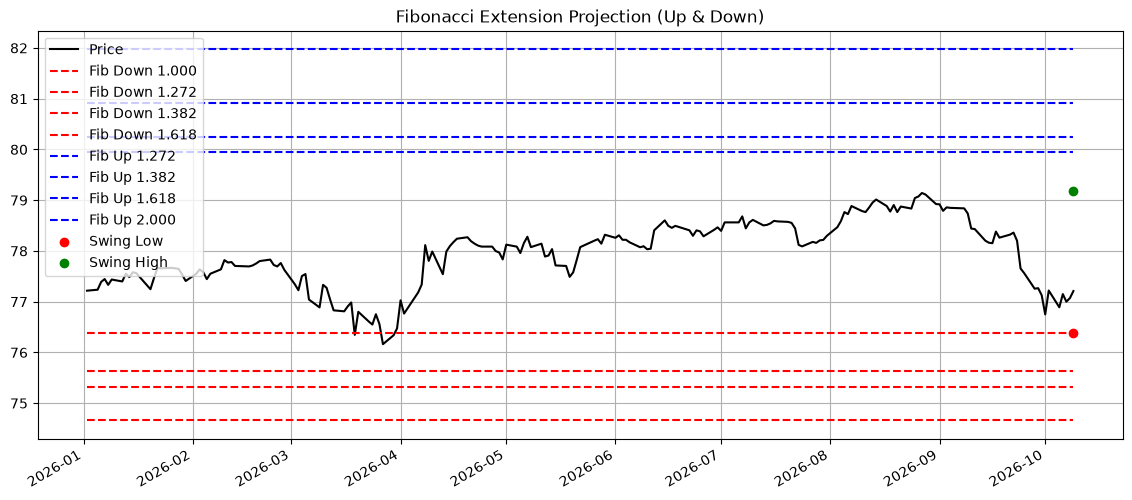

In [12]:
fib_result = fibonacci_extension.compute_fibonacci_extension(df.copy().reset_index())
fib_result

In [13]:
output_dir = Path("/workspace/data/figures/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{hyg}_fibonacci_extension_{dt.datetime.now().strftime('%Y-%m-%d')}.png"
fib_result["plot_obj"].savefig(output_path, dpi=300, bbox_inches="tight")